# The BO loop

Demonstrating functions in `bo_loop.py`, `acquisition.py` and `bo_plotting.py`

| part | content | 
|---|---|
| 1 | initial designs: Sobol, Latin hypercube, random | 
| 2-3 | test function, GP on the initial design | 
| 4-6 | EI vs LogEI, `torch.special.log_ndtr`, probability of feasibility | 
| 7-12 | the loop, saved data, plots, rebuilding the GP of a step | 
| 13 | BO vs random search over seeds, constraints |
| 14 | preferences from pairwise comparisons: `PreferenceGP` (probit), EI(x) * pi(x), known utilities |

Note: objectives are **maximised**, every model and plot takes inputs in original units.

In [1]:
import csv
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import display
from scipy.stats import norm, qmc

for folder in (Path.cwd(), Path.cwd().parent):          # find the package next to or above this notebook
    if (folder / "BOproj").is_dir():
        sys.path.insert(0, str(folder))
        ROOT = folder
        break

from BOproj.benchmarks import (ROSEN_BOUNDS, UTILITIES, ball, grid_optimum,
                               neg_rosenbrock, rosenbrock, u_polynomial)
from BOproj.bo_loop import BayesianOptimizer, initial_design, load_models
from BOproj.bo_plotting import plot_convergence
from BOproj.gp import ContinuousGP

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 100
RUNS = ROOT / "BOproj" / "runs" / "notebook"
bg = rosenbrock                                          # background for the maps: f itself
print("runs go to", RUNS)

runs go to /home/fabyk/THESIS/BOproj/runs/notebook


## 1. Initial design

`initial_design(bounds, n, method, seed)` gives the points evaluated before the first BO step (`n_init`, default 2(d+1)). Possible methods are **random**, **lhs**, **sobol**

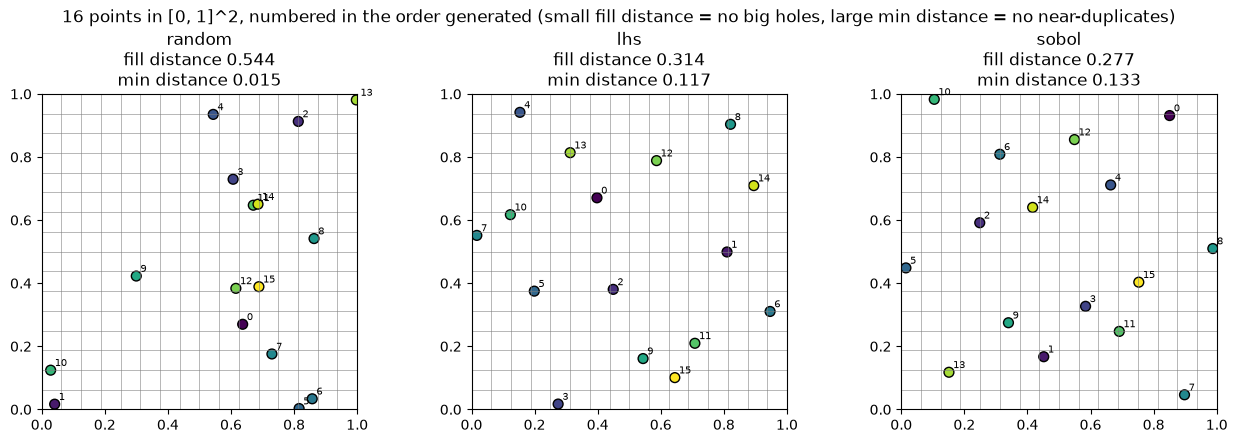

In [2]:
from scipy.spatial import cKDTree, distance #cKD


def design_quality(X, n_test=20000, seed=27):
    """Two plain numbers for a design X in [0, 1]^d.
    fill distance: from the worst-covered spot of the box to its nearest design point (smaller = no big holes);
    min distance: the closest pair of design points (larger = no near-duplicates)."""
    test_points = np.random.default_rng(seed).random((n_test, X.shape[1]))
    fill_distance = cKDTree(X).query(test_points)[0].max()
    return fill_distance, distance.pdist(X).min()


n = 16
fig, axes = plt.subplots(1, 3, figsize=(13, 4.3))
for axis, method in zip(axes, ("random", "lhs", "sobol")):
    X_start = initial_design([[0, 1], [0, 1]], n, method, seed=0)
    fill_distance, min_distance = design_quality(X_start)
    for t in np.linspace(0, 1, n + 1):
        axis.axvline(t, color="gray", lw=0.4)
        axis.axhline(t, color="gray", lw=0.4)
    axis.scatter(*X_start.T, c=np.arange(n), cmap="viridis", s=50, edgecolors="k")
    for i, x in enumerate(X_start):
        axis.annotate(str(i), x, fontsize=7, xytext=(3, 3), textcoords="offset points")
    axis.set(title=f"{method}\nfill distance {fill_distance:.3f}\nmin distance {min_distance:.3f}",
             xlim=(0, 1), ylim=(0, 1), aspect="equal")
fig.suptitle("16 points in [0, 1]^2, numbered in the order generated "
             "(small fill distance = no big holes, large min distance = no near-duplicates)")
plt.tight_layout()
plt.show()

**fill distance** shows how far the worst-covered spot of the box is from its nearest design point,
**minimum distance** is the minimum distance between two design points.
Fill distance is estimated from 20000 random test points. Both are in units of the unit square.

Classical measure of how even the distribution of points is is the **discrepancy** (Niederreiter 1992): how far the fraction of points in a box, `scipy.stats.qmc.discrepancy(X)` can be used. Plots for 200 random generations

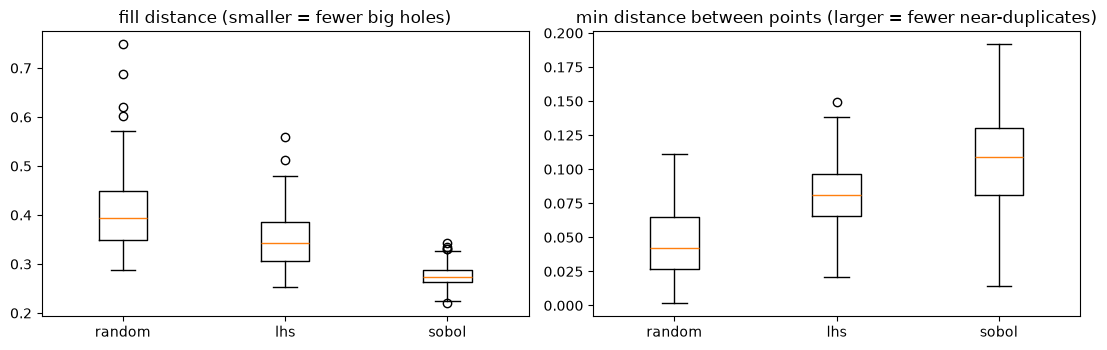

In [3]:
stats = {m: [] for m in ("random", "lhs", "sobol")}
for seed in range(200):
    for m in stats:
        X_start = initial_design([[0, 1], [0, 1]], 16, m, seed)
        stats[m].append(design_quality(X_start))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for k, (axis, label) in enumerate(zip(axes, ("fill distance (smaller = fewer big holes)",
                                              "min distance between points (larger = fewer near-duplicates)"))):
    axis.boxplot([np.array(v)[:, k] for v in stats.values()], tick_labels=list(stats))
    axis.set_title(label)
plt.tight_layout()
plt.show()

## 2. The test function

Rosenbrock: $f(x) = \sum_i 100\,(x_{i+1} - x_i^2)^2 + (1 - x_i)^2$, minimum $0$ at $(1, \dots, 1)$, on $[-2, 2]^2$.
The minimum lies in a long, flat, curved valley: easy to find the valley, hard to walk along it. The values span
$0$ to $\approx 3600$, so on the maps the valley is a thin dark line. The loop **maximises** `neg_rosenbrock` $= -f$.

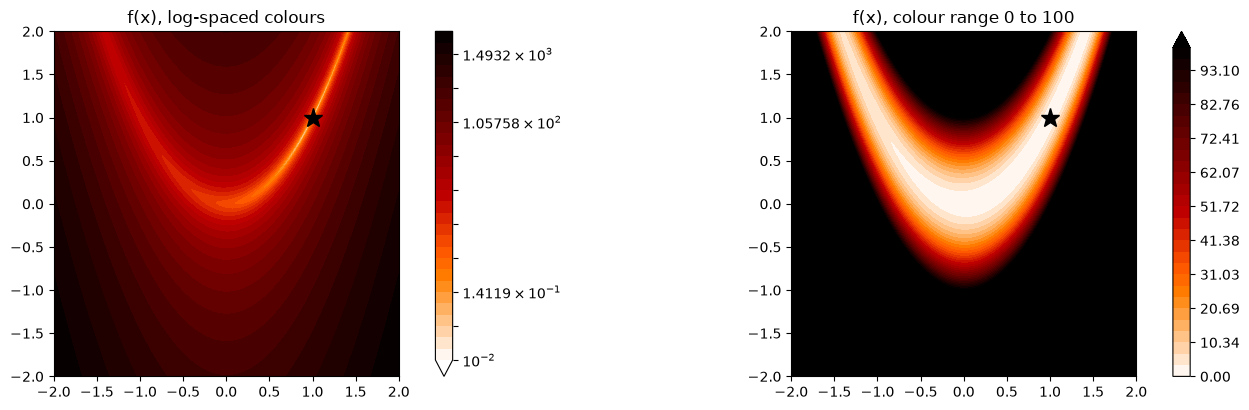

In [23]:
from matplotlib.colors import LogNorm

g = np.linspace(-2, 2, 300)
grid_x1, grid_x2 = np.meshgrid(g, g)
F = rosenbrock(np.c_[grid_x1.ravel(), grid_x2.ravel()]).reshape(grid_x1.shape)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
cs = axes[0].contourf(grid_x1, grid_x2, F, np.geomspace(0.01, F.max(), 30), norm=LogNorm(0.01, F.max()), extend="min",
                      cmap="gist_heat_r"); fig.colorbar(cs, ax=axes[0]); axes[0].set_title("f(x), log-spaced colours")
cs = axes[1].contourf(grid_x1, grid_x2, F, np.linspace(0, 100, 30), cmap="gist_heat_r", extend="max"); fig.colorbar(cs, ax=axes[1])
axes[1].set_title("f(x), colour range 0 to 100")
for axis in axes[:2]:
    axis.plot(1, 1, "k*", ms=14)
    axis.set_aspect("equal")
plt.tight_layout()
plt.show()

## GP on the initial design

The loop fits exactly this model at each step (`BayesianOptimizer.fit_models`): ARD Matern 5/2, inputs normalised to the unit
square with the bounds, outputs standardised. With 6 points the GP only sees the broad bowl; with 30 it starts to
see the valley.

The 2-d maps take `cmap=`: any matplotlib colour map name (as below) or a `Colormap` object. A name is enough, so you do not need to import matplotlib yourself.

n = 6: lengthscales [0.186 1.008] (normalised units), noise 2.59e+03


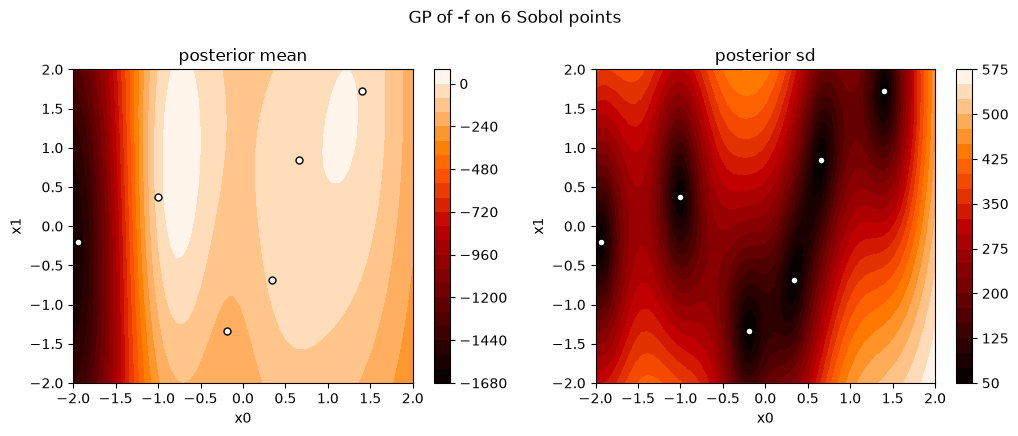

n = 30: lengthscales [0.313 0.807] (normalised units), noise 612


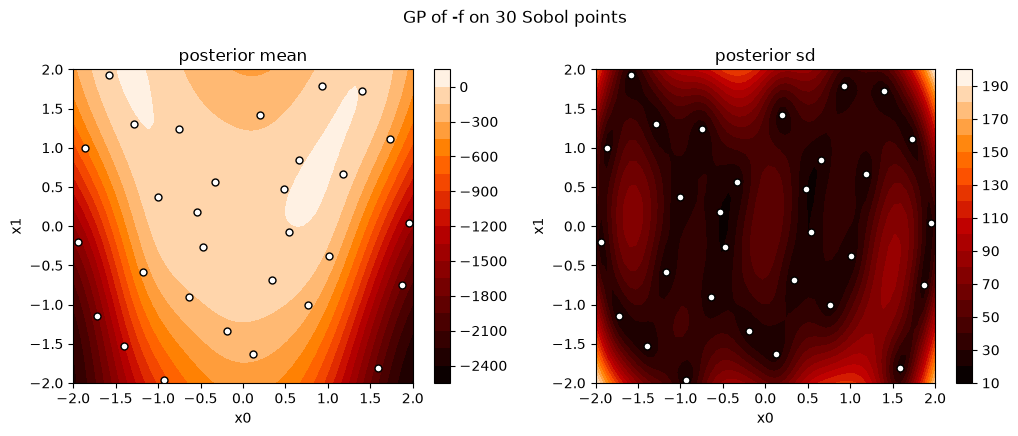

In [5]:
for n0 in (6, 30):
    X_start = initial_design(ROSEN_BOUNDS, n0, "sobol", seed=0)
    gp0 = ContinuousGP(bounds=ROSEN_BOUNDS).fit(X_start, neg_rosenbrock(X_start))

    print(f"n = {n0}: lengthscales {np.round(gp0.lengthscales(), 3)} (normalised units), noise {gp0.noise():.3g}")

    display(gp0.plot(
        title=f"GP of -f on {n0} Sobol points",
        cmap="gist_heat"
    ))

## 4. Expected improvement, and why the log version

With posterior mean $\mu$, sd $\sigma$ and incumbent $y^*$ (best value so far), $z = (\mu - y^*) / \sigma$:

$$\mathrm{EI}(x) = \mathbb{E}[\max(f(x) - y^*, 0)] = \sigma\,\big(z\,\Phi(z) + \varphi(z)\big)$$

If z is too small and we don't use the logEI, things break...

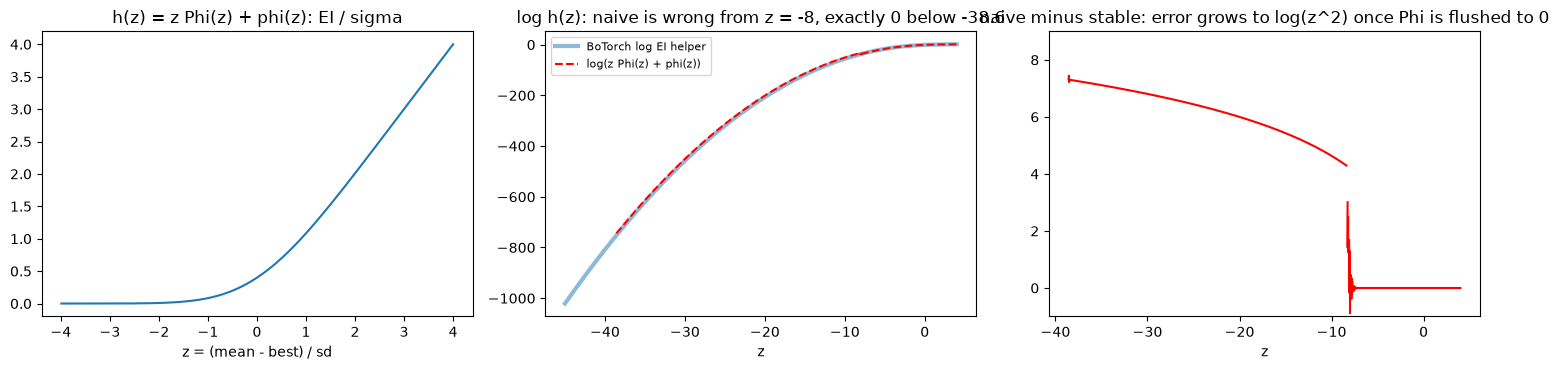

naive h(-40) = 0.0    stable log h(-40) = -808.3119228325023


In [6]:
from botorch.acquisition.analytic import _log_ei_helper      # BoTorch's log h(z), used by LogExpectedImprovement

z = np.linspace(-45, 4, 3000)
zt = torch.tensor(z)                                       # naive EI 
h_naive = (zt * torch.distributions.Normal(0.0, 1.0).cdf(zt) + torch.exp(-zt ** 2 / 2) / np.sqrt(2 * np.pi)).numpy()
with np.errstate(divide="ignore", invalid="ignore"):
    log_naive = np.log(h_naive)
log_bt = _log_ei_helper(torch.tensor(z)).numpy()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
m = z > -4
axes[0].plot(z[m], h_naive[m])
axes[0].set(title="h(z) = z Phi(z) + phi(z): EI / sigma", xlabel="z = (mean - best) / sd")
axes[1].plot(z, log_bt, lw=3, alpha=0.5, label="BoTorch log EI helper")
axes[1].plot(z, log_naive, "r--", label="log(z Phi(z) + phi(z))")
axes[1].set(title="log h(z): naive is wrong from z = -8, exactly 0 below -38.6", xlabel="z")
axes[1].legend(fontsize=8)
axes[2].plot(z, log_naive - log_bt, "r")
axes[2].set(title="naive minus stable: error grows to log(z^2) once Phi is flushed to 0", xlabel="z", ylim=(-1, 9))
plt.tight_layout()
plt.show()
print("naive h(-40) =", h_naive[np.argmin(abs(z + 40))], "   stable log h(-40) =", log_bt[np.argmin(abs(z + 40))])

## 5. `torch.special.log_ndtr`

The probability of feasibility of a constraint $c(x) \le 0$ is $\Phi(-\mu_c / \sigma_c)$, and the acquisition works with its log.
`torch.log(torch.special.ndtr(z))` is replaced `torch.special.log_ndtr(z)` for numerical reasons.

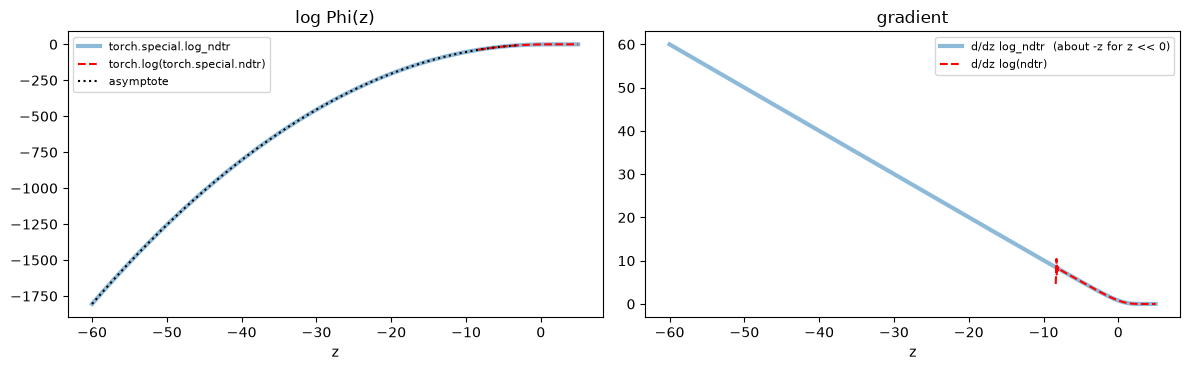

at z = -50:  log_ndtr = -1254.8313611394199   log(ndtr) = -inf


In [7]:
zt = torch.linspace(-60, 5, 2000, dtype=torch.float64, requires_grad=True)
stable = torch.special.log_ndtr(zt)
naive = torch.log(torch.special.ndtr(zt))
g_stable, = torch.autograd.grad(stable.sum(), zt)
g_naive, = torch.autograd.grad(naive.sum(), zt)
zz = zt.detach().numpy()
asym = -zz ** 2 / 2 - np.log(-np.minimum(zz, -1e-9)) - 0.5 * np.log(2 * np.pi)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(zz, stable.detach(), lw=3, alpha=0.5, label="torch.special.log_ndtr")
axes[0].plot(zz, naive.detach(), "r--", label="torch.log(torch.special.ndtr)")
axes[0].plot(zz[zz < -3], asym[zz < -3], "k:", label="asymptote")
axes[0].set(title="log Phi(z)", xlabel="z")
axes[0].legend(fontsize=8)
axes[1].plot(zz, g_stable, lw=3, alpha=0.5, label="d/dz log_ndtr  (about -z for z << 0)")
axes[1].plot(zz, g_naive, "r--", label="d/dz log(ndtr)")
axes[1].set(title="gradient", xlabel="z")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()
print("at z = -50:  log_ndtr =", float(torch.special.log_ndtr(torch.tensor(-50.0, dtype=torch.float64))),
      "  log(ndtr) =", float(torch.log(torch.special.ndtr(torch.tensor(-50.0, dtype=torch.float64)))))

## 6. Probability of feasibility from a constraint GP

Each constraint $c_i(x) \le 0$ gets its own `ContinuousGP`, and $\mathrm{PoF}_i(x) = \Phi(-\mu_i(x)/\sigma_i(x))$
(`LogEIProduct.log_pof`). Here the constraint is `ball`: $|x|^2 \le 2$

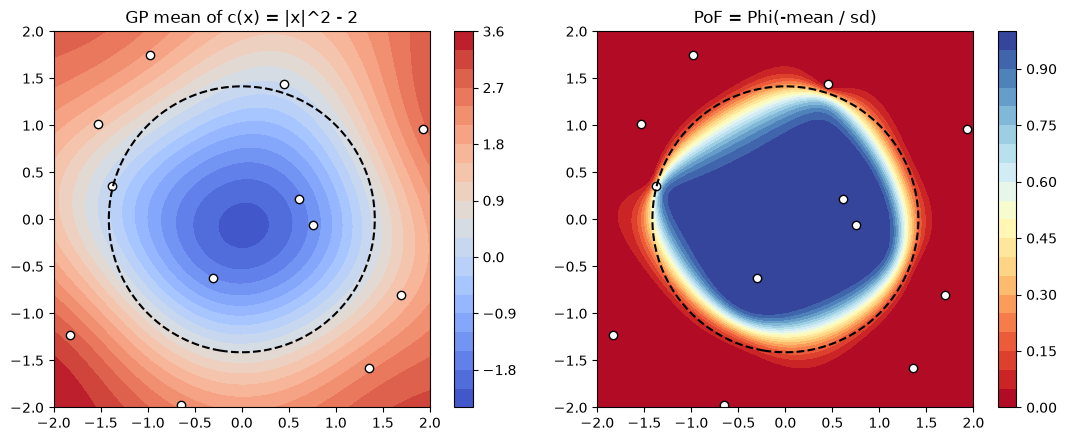

In [ ]:
X_start = initial_design(ROSEN_BOUNDS, 12, "sobol", seed=1)
c_gp = ContinuousGP(bounds=ROSEN_BOUNDS).fit(X_start, ball(X_start))
h = np.linspace(-2, 2, 80)                    # GP predictions build an n x n covariance: keep n = 80^2, not 300^2
reduced_x1, reduced_x2 = np.meshgrid(h, h)
X_reduced = np.c_[reduced_x1.ravel(), reduced_x2.ravel()]
m, v = c_gp.predict(X_reduced)
pof = norm.cdf(-m / np.sqrt(v)).reshape(reduced_x1.shape)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
cs = axes[0].contourf(reduced_x1, reduced_x2, m.reshape(reduced_x1.shape), 20, cmap="coolwarm"); fig.colorbar(cs, ax=axes[0])
axes[0].set_title("GP mean of c(x) = |x|^2 - 2")
cs = axes[1].contourf(reduced_x1, reduced_x2, pof, np.linspace(0, 1, 21), cmap="RdYlBu"); fig.colorbar(cs, ax=axes[1])
axes[1].set_title("PoF = Phi(-mean / sd)")
for axis in axes:
    axis.contour(reduced_x1, reduced_x2, ball(X_reduced).reshape(reduced_x1.shape), [0], colors="k", linestyles="--")
    axis.scatter(*X_start.T, c="w", edgecolors="k")
    axis.set_aspect("equal")
plt.tight_layout()
plt.show()

## 7. Running the loop

`BayesianOptimizer(objective, bounds, ...).run(n_iter)`: `n_init` initial points, then `n_iter` steps of
*fit GPs -> maximise log EI (+ log PoF + log pi) -> evaluate*. Everything is saved to `run_dir` after every evaluation.

In [9]:
opt = BayesianOptimizer(neg_rosenbrock, ROSEN_BOUNDS, init="sobol", seed=0, run_dir=RUNS / "rosen2d",
              f_optimum=0.0, x_optimum=[1.0, 1.0]).run(n_iter=40)
best_x, best_y = opt.best()
print(f"{len(opt.y)} evaluations; best x = {np.round(best_x, 4)}, f = {-best_y:.5f}, distance to (1, 1) = {np.linalg.norm(best_x - 1):.4f}")

46 evaluations; best x = [0.9524 0.9022], f = 0.00461, distance to (1, 1) = 0.1088


## 8. What was saved

| file | contents |
|---|---|
| `config.json` | all settings, seed, initial-design method, library versions |
| `history.csv` | one row per evaluation: x, y, feasible, best y so far, regret, distance to the optimum, the GP's prediction at x **before** evaluating it, the **acquisition value of the recommended point**, PoF, pi, **GP hyperparameters**, timings |
| `data.npz` | X, y, C, `X_pref` and every comparison the DM made (`pairs_a` vs `pairs_b`, who won) |
| `models/iter_###.pt` | the GPs that chose a certain evaluation, to reload with `load_models` |
| `summary.json` | best point, value, regret, distance |

In [10]:
run_dir = RUNS / "rosen2d"
print(sorted(p.name for p in run_dir.iterdir()), " +", len(list((run_dir / "models").iterdir())), "model files")
print(json.dumps(json.loads((run_dir / "summary.json").read_text()), indent=1))
rows = list(csv.DictReader(open(run_dir / "history.csv")))
print("columns:", list(rows[0]))
for r in rows[5:9]:                      # last initial point, first BO steps
    print({k: (round(float(v), 4) if v not in ("", "True", "False", "init", "bo") else v) for k, v in r.items()
           if k in ("eval", "phase", "x1", "x2", "y", "best_y", "pred_mean", "pred_sd", "acq_value", "ls1", "ls2", "noise")})
data = np.load(run_dir / "data.npz")
print({k: data[k].shape for k in data.files})

['config.json', 'data.npz', 'history.csv', 'models', 'summary.json']  + 40 model files
{
 "n_evals": 46,
 "n_feasible": 46,
 "n_comparisons": 0,
 "best_x": [
  0.9523663285790781,
  0.9021676980365206
 ],
 "best_y": -0.004605650492540083,
 "regret": 0.004605650492540083,
 "dist_to_opt": 0.10881234286839779,
 "time_s": 31.26080846786499
}
columns: ['eval', 'phase', 'x1', 'x2', 'y', 'feasible', 'best_y', 'regret', 'dist_to_opt', 'wall_time', 'pred_mean', 'pred_sd', 'acq_value', 'pof', 'pi', 'ls1', 'ls2', 'noise', 't_fit', 't_acq']
{'eval': 5.0, 'phase': 'init', 'x1': -1.9413, 'x2': -0.2061, 'y': -1588.5587, 'best_y': -5.9747, 'pred_mean': '', 'pred_sd': '', 'acq_value': '', 'ls1': '', 'ls2': '', 'noise': ''}
{'eval': 6.0, 'phase': 'bo', 'x1': -0.5755, 'x2': 2.0, 'y': -280.9683, 'best_y': -5.9747, 'pred_mean': -2.6632, 'pred_sd': 407.8828, 'acq_value': 5.1022, 'ls1': 0.1864, 'ls2': 1.0081, 'noise': 2588.6646}
{'eval': 7.0, 'phase': 'bo', 'x1': 1.0711, 'x2': -2.0, 'y': -990.4918, 'best_y':

## 9. Where points have been sampled, convergence

`opt.plot_points(...)`: initial design (squares), BO points coloured by step, the optimum (star) and the best design
found (X). `opt.plot_convergence()`: regret $f^* - y^*_n$ and the distance from the best design to the optimal
location, on log scales.

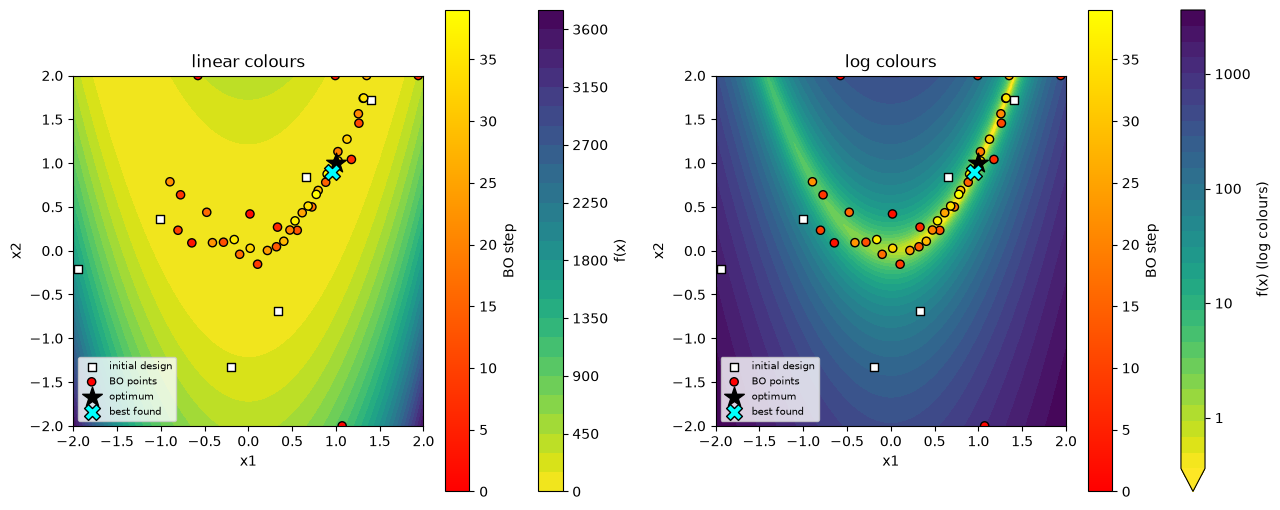

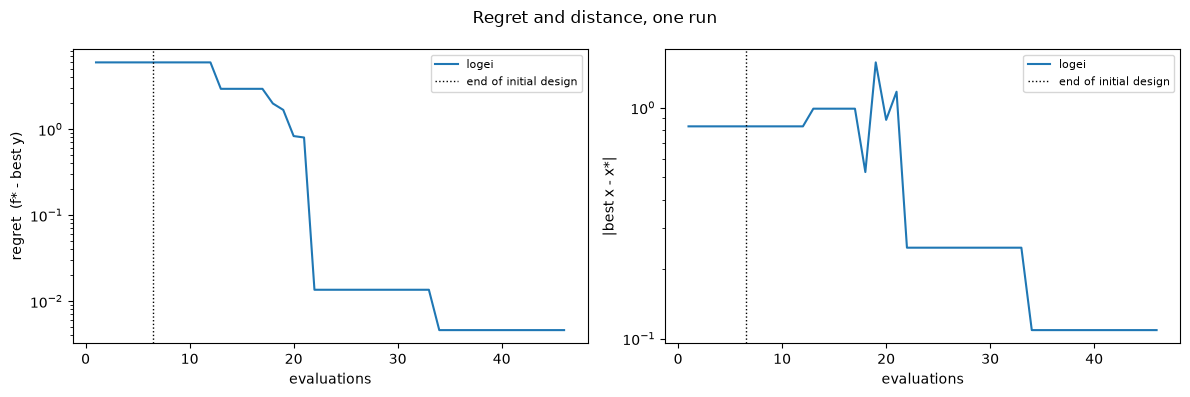

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
opt.plot_points(ax=axes[0], background=bg, background_label="f(x)", title="linear colours")
opt.plot_points(ax=axes[1], background=bg, background_label="f(x)", background_scale="log", title="log colours")
plt.tight_layout()
plt.show()
display(opt.plot_convergence(title="Regret and distance, one run"))

## 10. Diagnostics

`opt.plot_diagnostics()`: observations and incumbent; **calibration** (the prediction made before each evaluation vs
what was observed, $\pm 2$ sd); the standardised error, which for a calibrated model stays within $\pm 2$ about 95% of
the time; the lengthscales (in normalised units: 1 = the width of the box); the acquisition value at the chosen point; time per step.

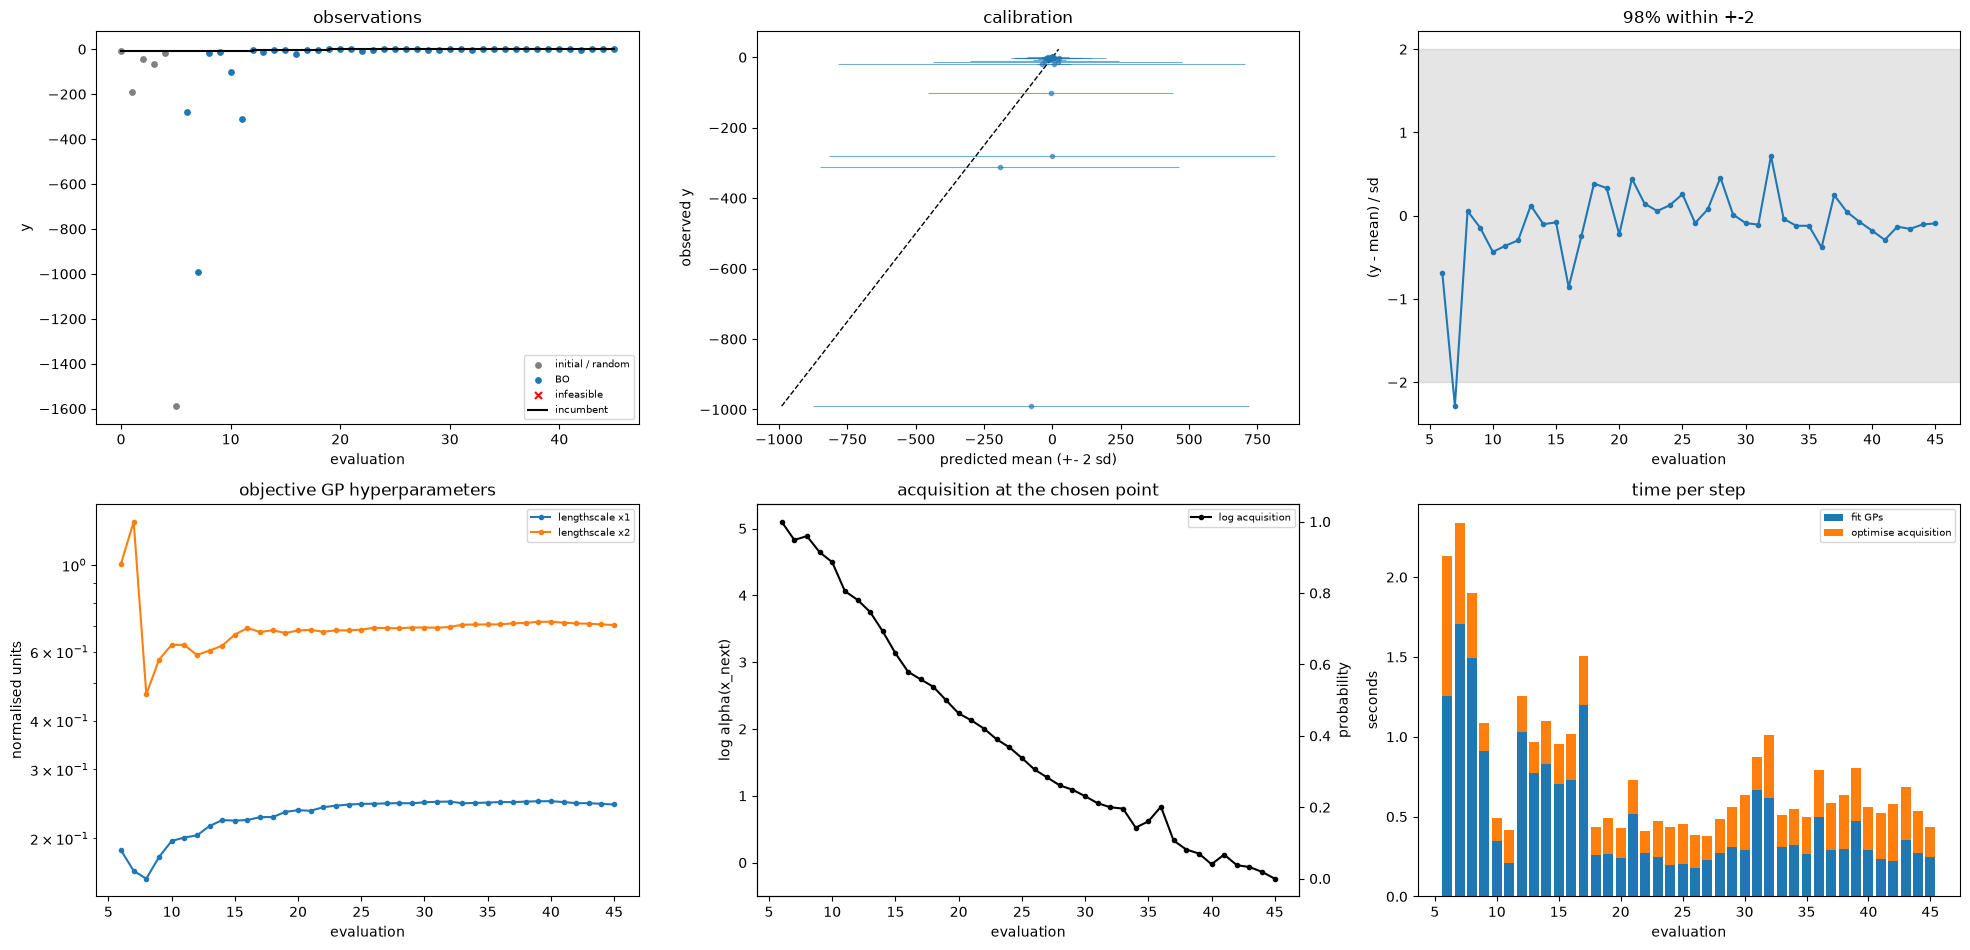

In [12]:
display(opt.plot_diagnostics())

## 11. The acquisition function at several steps

`opt.plot_acquisition(n=k)` refits the models on the first k evaluations and draws log EI on a grid, with the point the
loop actually chose as evaluation k (red star).

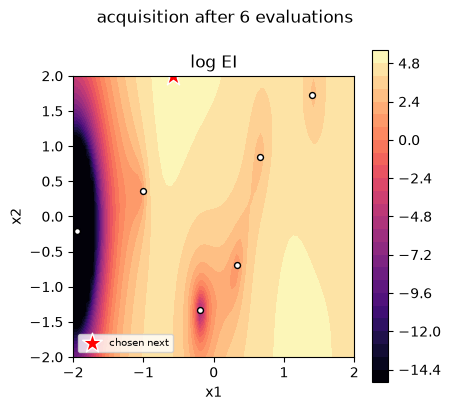

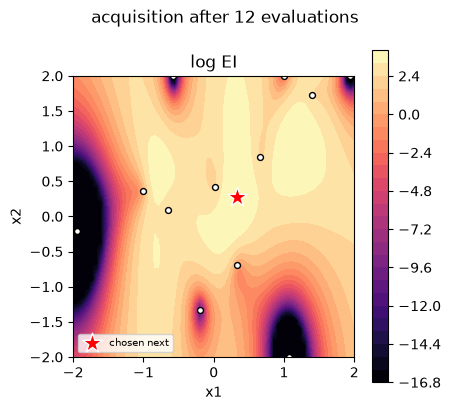

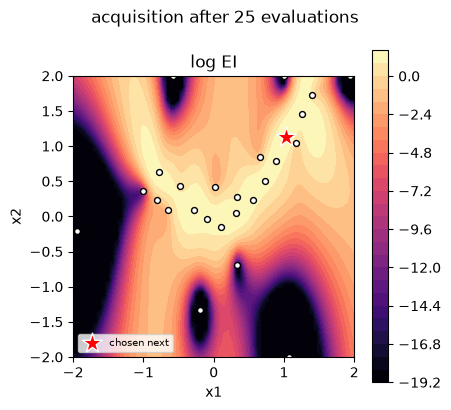

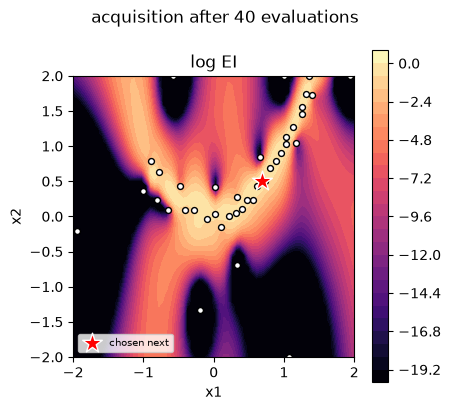

In [13]:
for k in (6, 12, 25, 40):
    display(opt.plot_acquisition(n=k))

## 12. Rebuilding the GP of any step: `load_models(run_dir, k)`

returns the GPs that chose evaluation k, exactly as the loop fitted them: `Models(objective, constraints, preference)`
(in the same session they are also in `opt.models[k]`). All the `gp.py` tools apply: here `ContinuousGP.plot` as a map
and as a 1-d slice through the optimum with the truth dashed.

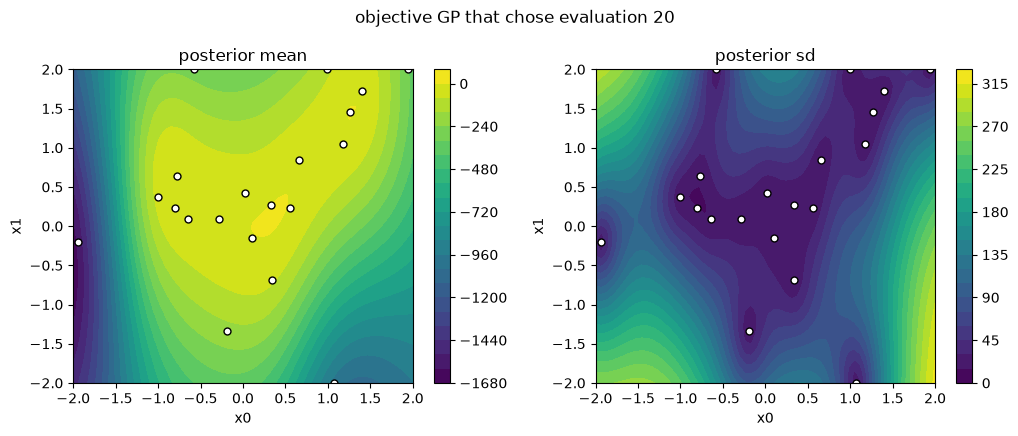

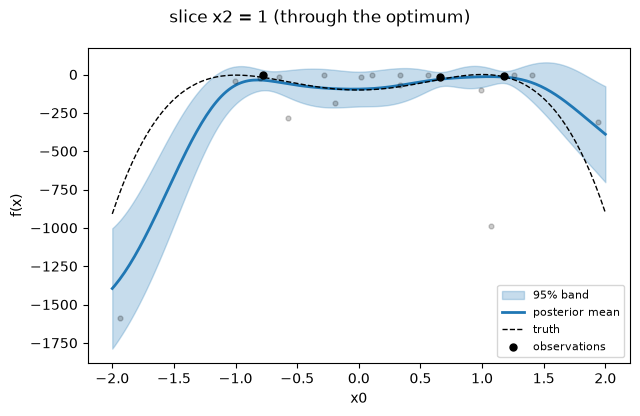

In [14]:
f_gp_k = load_models(RUNS / "rosen2d", 20).objective
display(f_gp_k.plot(title="objective GP that chose evaluation 20"))
display(f_gp_k.plot(dims=[0], fixed=[0.0, 1.0], truth=neg_rosenbrock, title="slice x2 = 1 (through the optimum)"))

## 13. BO vs random search over seeds, with a constraint

`plot_convergence` takes one optimiser, a list (median and quartiles over seeds) or `{label: list}`. Random search uses the same
`BayesianOptimizer` with `strategy="random"`, so its results are saved in the same format.

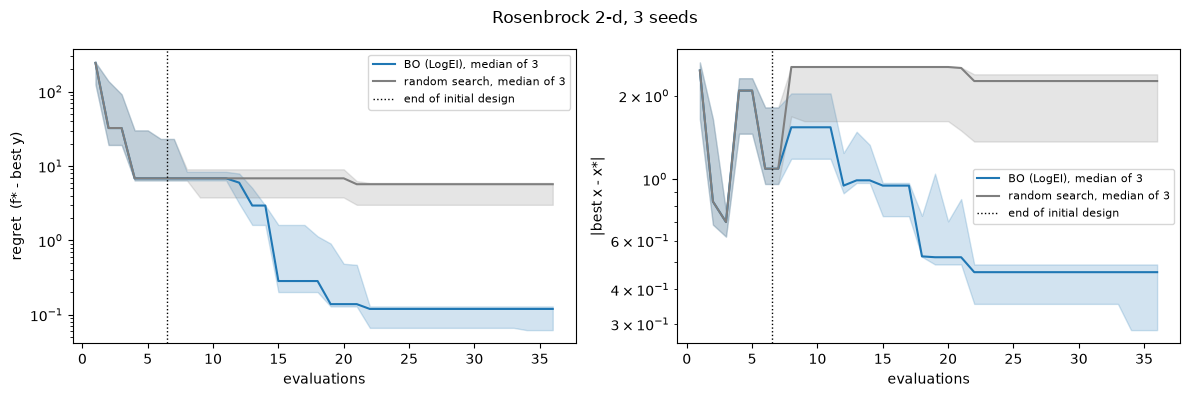

In [15]:
runs = {"BO (LogEI)": [], "random search": []}
for seed in range(3):
    runs["BO (LogEI)"].append(BayesianOptimizer(neg_rosenbrock, ROSEN_BOUNDS, seed=seed, f_optimum=0.0, x_optimum=[1, 1],
                                     run_dir=RUNS / f"bo_seed{seed}").run(30))
    runs["random search"].append(BayesianOptimizer(neg_rosenbrock, ROSEN_BOUNDS, seed=seed, f_optimum=0.0, x_optimum=[1, 1],
                                        strategy="random", run_dir=RUNS / f"random_seed{seed}").run(30))
display(plot_convergence(runs, title="Rosenbrock 2-d, 3 seeds"))

With the constraint $|x|^2 \le 2$: the acquisition is now log EI + log PoF, and the incumbent is the best **feasible** value.
Empty markers are infeasible evaluations

5 of 36 evaluations infeasible; best feasible x = [0.9933 0.977 ]


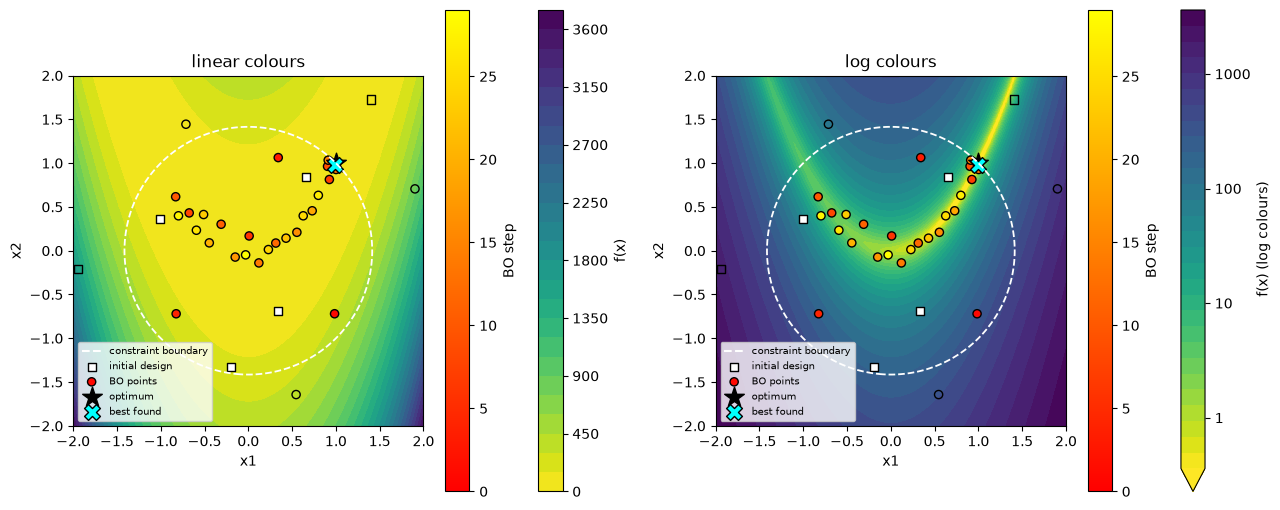

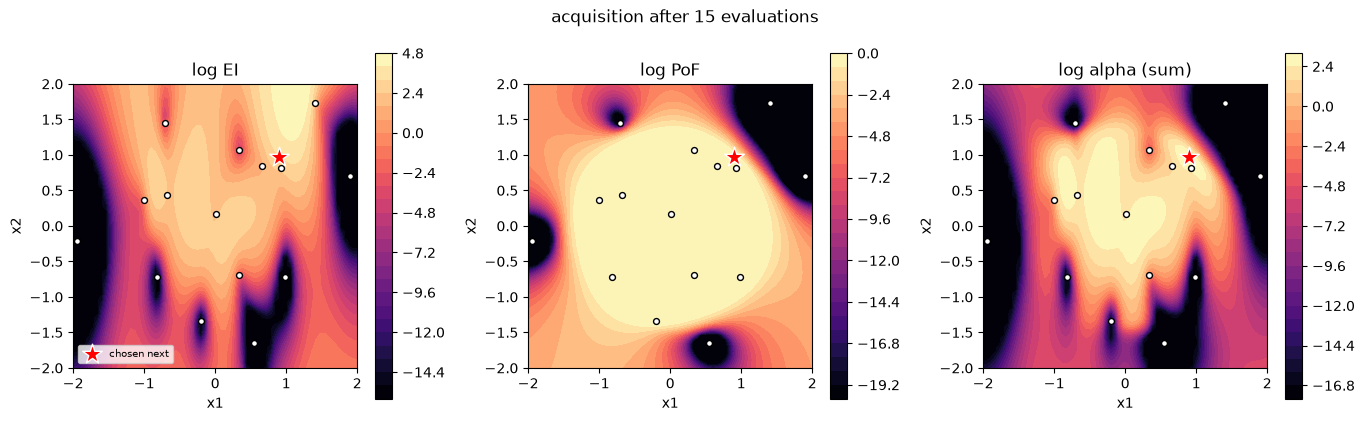

In [16]:
con_opt = BayesianOptimizer(neg_rosenbrock, ROSEN_BOUNDS, constraints=[ball], seed=0, f_optimum=0.0, x_optimum=[1, 1],
             run_dir=RUNS / "rosen2d_con").run(30)
print(f"{(~con_opt.feasible).sum()} of {len(con_opt.y)} evaluations infeasible; best feasible x = {np.round(con_opt.best()[0], 4)}")
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
con_opt.plot_points(ax=axes[0], background=bg, background_label="f(x)", title="linear colours")
con_opt.plot_points(ax=axes[1], background=bg, background_label="f(x)", background_scale="log", title="log colours")
plt.tight_layout()
plt.show()
display(con_opt.plot_acquisition(n=15))

## 14. Preferences: maximise EI(x) * pi(x)

The decision maker (DM) compares two designs and says which is better. A `PreferenceGP` learns a hidden utility $u(x)$ from the answers, and the probit link (Chu and Ghahramani's likelihood, $\Phi$ of a utility difference) turns it into a probability $\pi(x)$ between 0 and 1. The loop then maximises (2.3)

$$\log \alpha(x) = \log \mathrm{EI}(x) + \log \pi(x) \quad (+ \textstyle\sum_i \log \mathrm{PoF}_i(x)).$$

The simulated DM (`PairwiseLabeler`) knows a utility $u$ and prefers the design with the larger $u$. The optimiser never sees $u$, only the answers. 14a-14c look at the model alone; 14e runs the loop with $\pi(x) = \mathbb{E}[\Phi(u(x))]$.

### 14a. What a `PreferenceGP` learns from comparisons (2.1)

A helper simulates the DM comparing random pairs of designs and fits a `PreferenceGP` to the answers. For each of the three utilities in `benchmarks.UTILITIES`, three maps on the same 0-1 scale (the white dashed line is $u = 0$): $\Phi(u(x))$ of the true utility; the score the GP returns, $\mathbb{E}[\Phi(u(x))]$ (`PreferenceGP.prob_torch`, which averages over the GP's uncertainty); and the plug-in $\Phi(\text{GP mean})$, which ignores the uncertainty. 40 comparisons.

linear       outputscale      66,  posterior sd of u from 6 to 6,  GP mean from -26 to 25


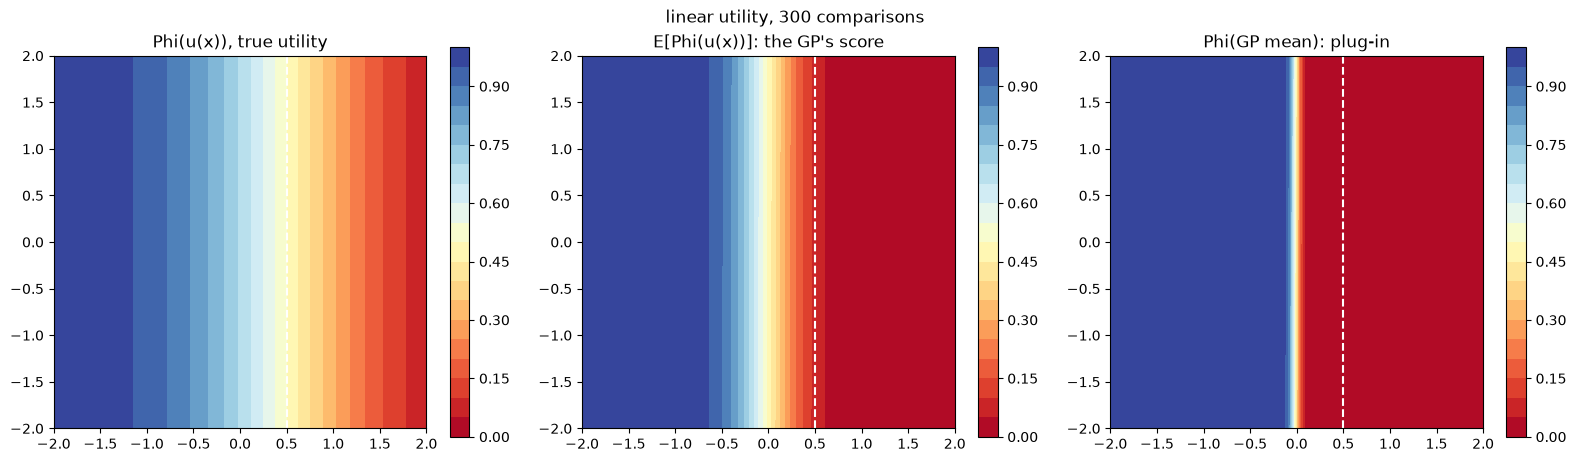

polynomial   outputscale     217,  posterior sd of u from 10 to 11,  GP mean from -8 to 46


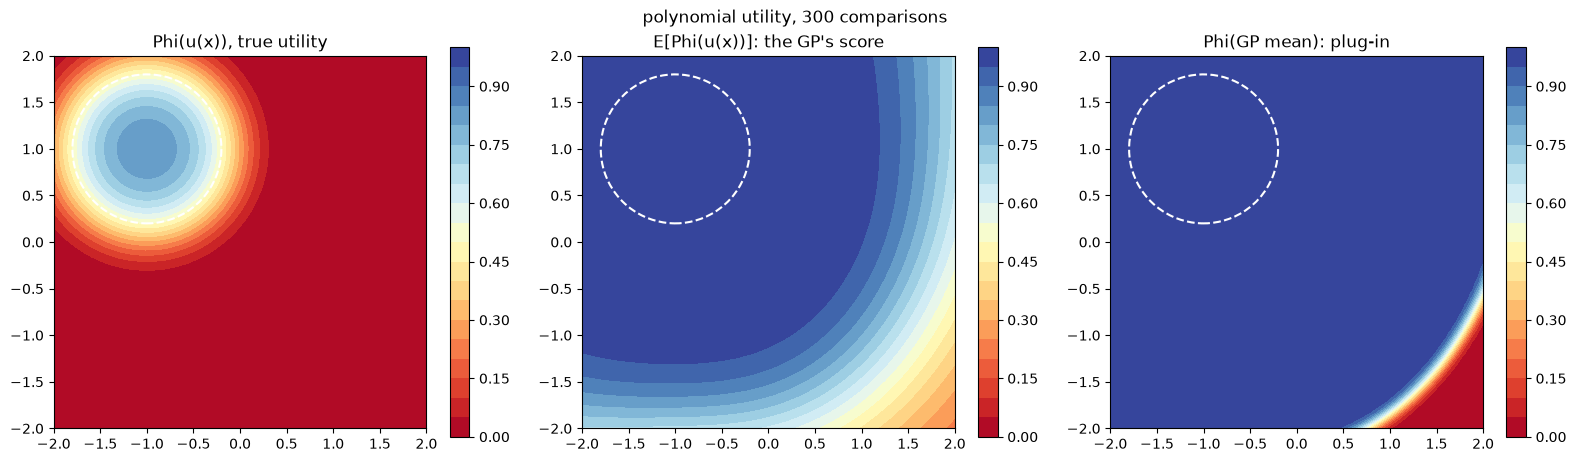

exponential  outputscale      81,  posterior sd of u from 6 to 7,  GP mean from -25 to 24


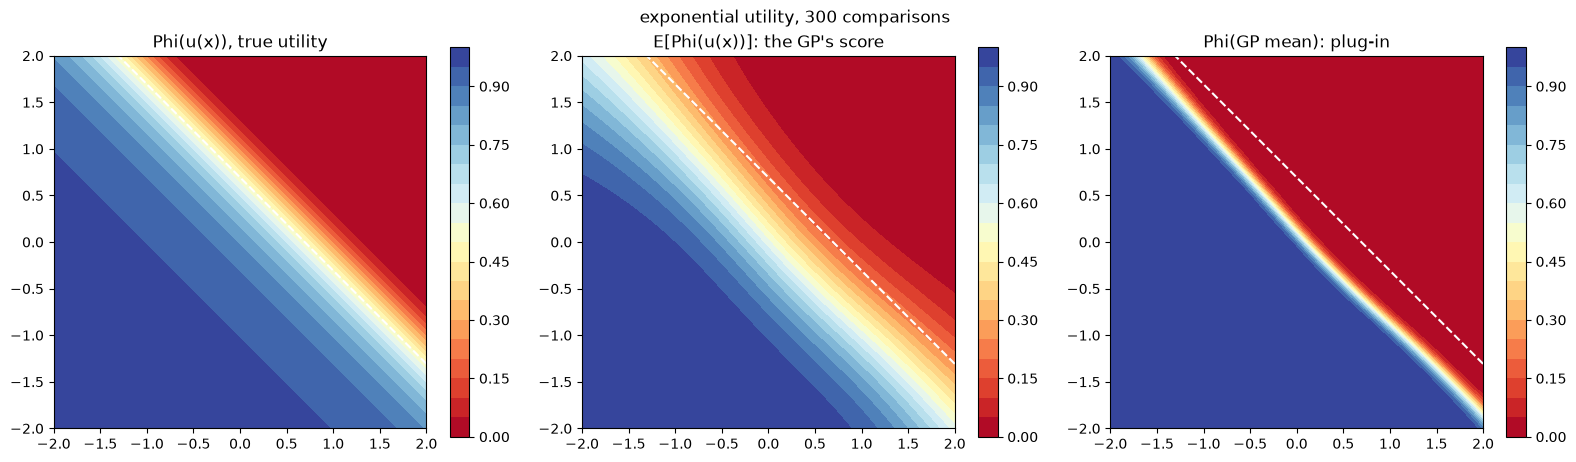

In [17]:
from BOproj.benchmarks import PairwiseLabeler
from BOproj.gp import PreferenceGP


def compare_and_fit(utility, n_comparisons, n_designs=40, seed=27):
    """The DM compares n_comparisons random pairs among n_designs lhs designs; a PreferenceGP is fitted to the answers."""
    designs = initial_design(ROSEN_BOUNDS, n_designs, "lhs", seed=seed)
    rng = np.random.default_rng(seed)
    first = rng.integers(0, n_designs, n_comparisons)
    second = (first + rng.integers(1, n_designs, n_comparisons)) % n_designs        # never a design against itself
    first_wins = PairwiseLabeler(utility)(designs[first], designs[second])
    return PreferenceGP(bounds=ROSEN_BOUNDS, link="probit").fit(designs[first], designs[second], first_wins)


line = np.linspace(-2, 2, 70)
map_x1, map_x2 = np.meshgrid(line, line)
X_map = np.c_[map_x1.ravel(), map_x2.ravel()]


def draw(axis, values, title, utility, cmap="viridis", levels=20):
    shown = axis.contourf(map_x1, map_x2, values.reshape(map_x1.shape), levels, cmap=cmap)
    axis.figure.colorbar(shown, ax=axis)
    axis.contour(map_x1, map_x2, utility(X_map).reshape(map_x1.shape), [0], colors="w", linestyles="--")
    axis.set_title(title)
    axis.set_aspect("equal")


probability_levels = np.linspace(0, 1, 21)
for name, utility in UTILITIES.items():
    pref_gp = compare_and_fit(utility, 300)
    mean, var = pref_gp.predict(X_map)
    print(f"{name:12s} outputscale {float(pref_gp.model.covar_module.outputscale):7.0f},  "
          f"posterior sd of u from {np.sqrt(var).min():.0f} to {np.sqrt(var).max():.0f},  GP mean from {mean.min():.0f} to {mean.max():.0f}")
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
    draw(axes[0], norm.cdf(utility(X_map)), "Phi(u(x)), true utility", utility, "RdYlBu", probability_levels)
    draw(axes[1], pref_gp.prob_torch(X_map).detach().numpy(), "E[Phi(u(x))]: the GP's score", utility, "RdYlBu",
         probability_levels)
    draw(axes[2], norm.cdf(mean), "Phi(GP mean): plug-in", utility, "RdYlBu", probability_levels)
    fig.suptitle(f"{name} utility, 300 comparisons")
    plt.tight_layout()
    plt.show()

The module's own plot, `PreferenceGP.plot()`: the learned utility (GP mean) with an arrow from the loser to the winner of each comparison (the first 25 are drawn), polynomial utility, 100 comparisons among 40 designs.

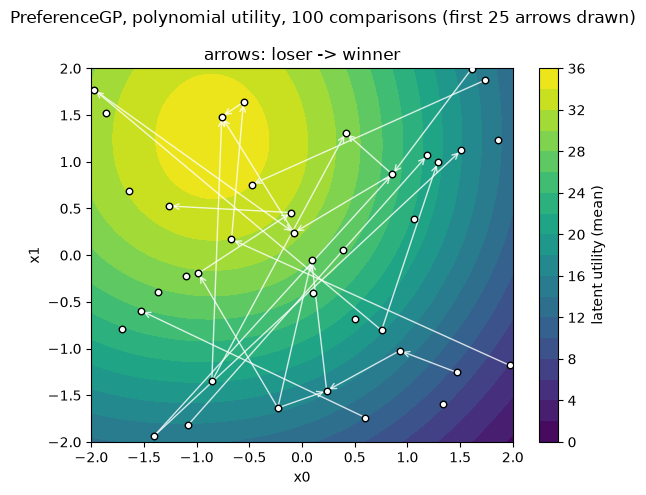

In [18]:
display(compare_and_fit(u_polynomial, 100).plot(title="PreferenceGP, polynomial utility, 100 comparisons (first 25 arrows drawn)"))

### 14b. How well the learned utility ranks designs (2.1)

The polynomial utility with 10, 30 and 80 comparisons: maps of the learned utility (GP mean) next to the true one. Then, on 1000 random designs, a scatter of learned against true utility (a monotone cloud means the ranking is right, whatever the scale).

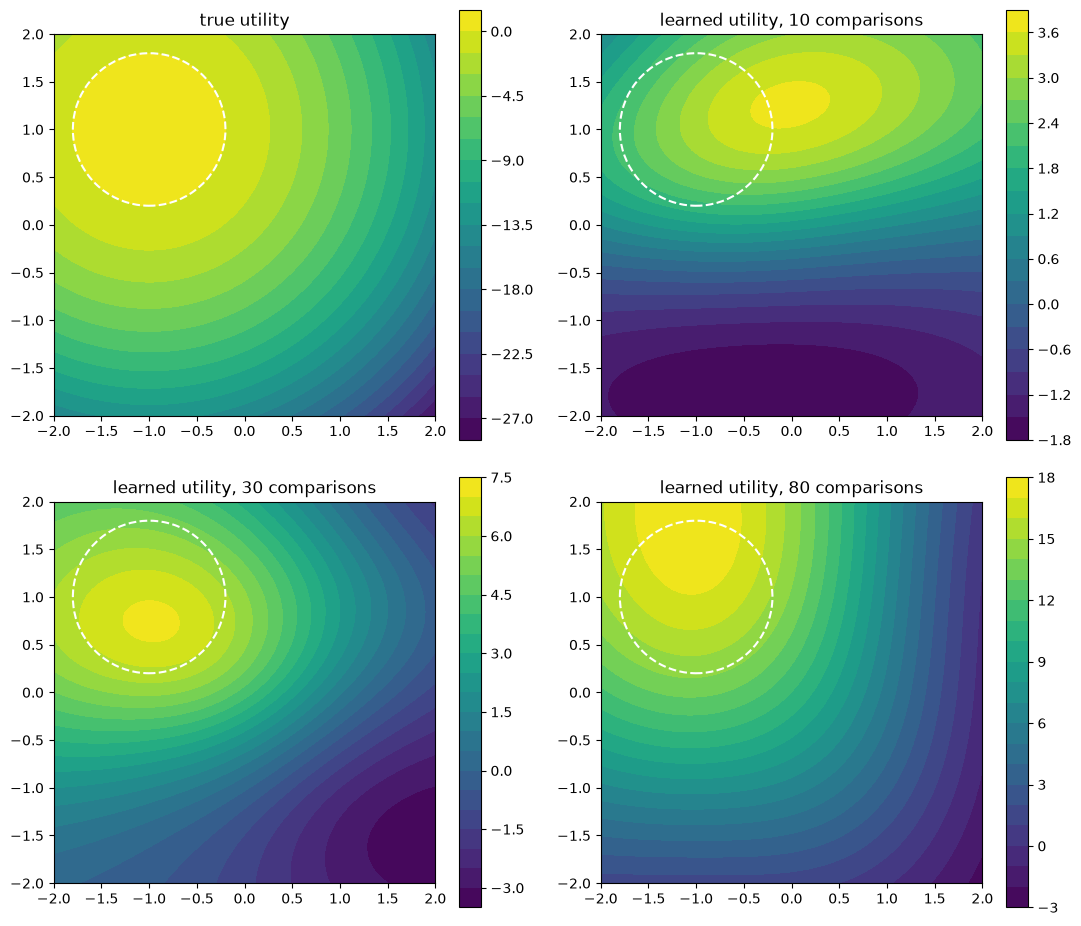

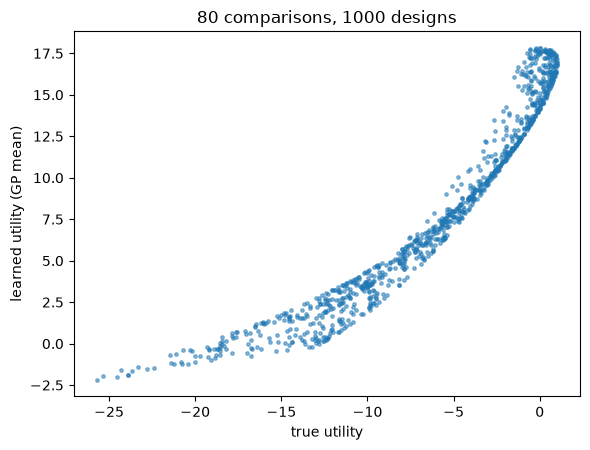

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9.5))
draw(axes[0, 0], u_polynomial(X_map), "true utility", u_polynomial)
for axis, n in zip(axes.ravel()[1:], (10, 30, 80)):
    draw(axis, compare_and_fit(u_polynomial, n).predict(X_map)[0], f"learned utility, {n} comparisons", u_polynomial)
plt.tight_layout()
plt.show()

test_X = initial_design(ROSEN_BOUNDS, 1000, "random", seed=99)
plt.figure(figsize=(6, 4.6))
plt.scatter(u_polynomial(test_X), compare_and_fit(u_polynomial, 80).predict(test_X)[0], s=6, alpha=0.5)
plt.xlabel("true utility")
plt.ylabel("learned utility (GP mean)")
plt.title("80 comparisons, 1000 designs")
plt.tight_layout()
plt.show()

### 14c. From utility to a score: the probit (2.2)

Two ways to turn the learned utility into $\pi(x) \in [0, 1]$, both in closed form with gradients, so the optimiser can use them:

* **the probit of the utility itself:** $\pi(x) = \mathbb{E}[\Phi(u(x))]$, with the GP's uncertainty about $u(x)$ averaged out (`PreferenceGP.prob_torch`). **This is what the loop uses.** Comparisons only fix differences of $u$, so its zero comes from the GP's prior, not from the DM.
* **against another design $x_0$:** $\pi(x) = P(u(x) > u(x_0))$, the probit of the utility *difference*, $\Phi\big((u(x) - u(x_0))/\sqrt{2}\big)$ with the uncertainty of the difference averaged out (`PreferenceGP.prob_better_torch`). $\pi = 0.5$ at $x_0$. The first figures show it for 6, 20 and 80 comparisons (polynomial utility) with $x_0 = (-0.2, 1)$, a design on the edge of the region the DM likes, and with $x_0 = (1, 1)$, a design the DM dislikes; the last panel is the truth (1 where the DM prefers $x$ to $x_0$). The dashed line is $u = 0$.

The last figure is the first option, for 80 comparisons, next to the truth $u > 0$.

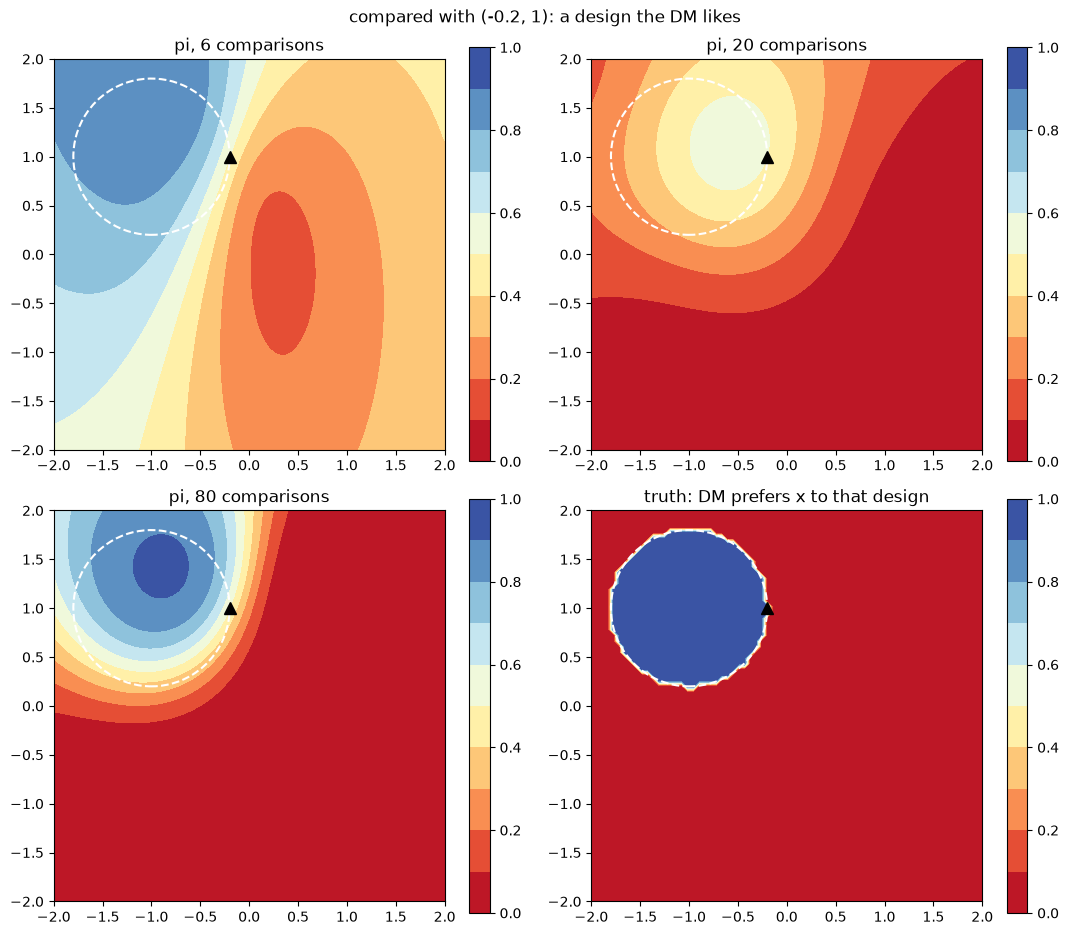

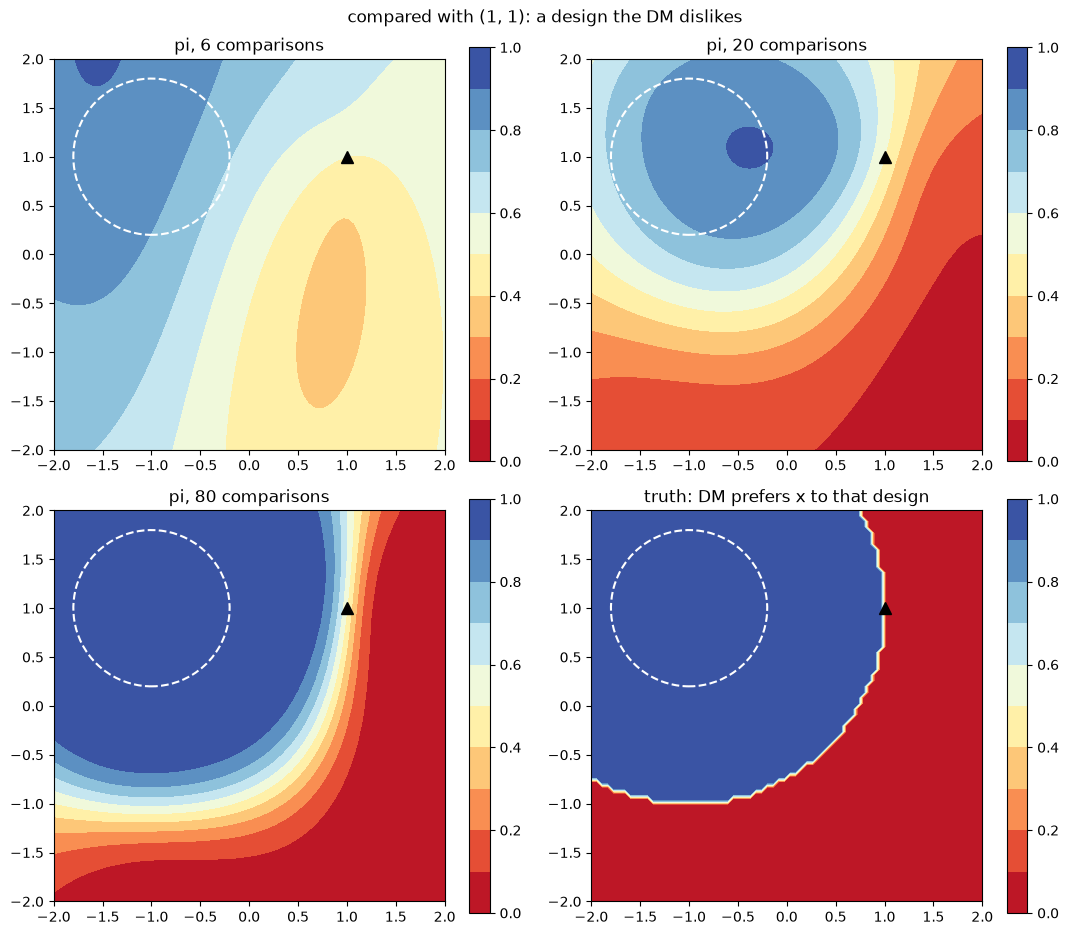

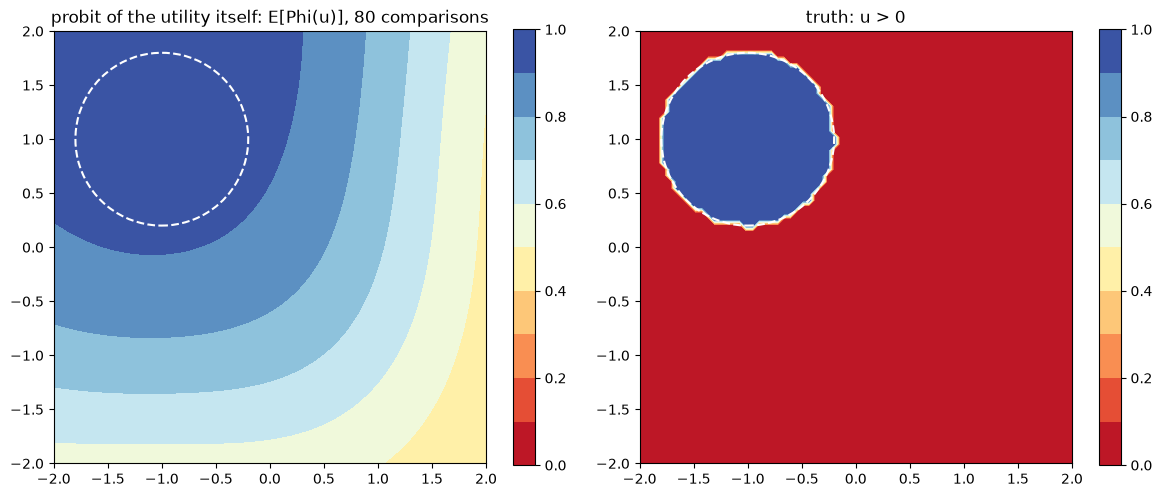

In [20]:
liked_design = np.array([-0.2, 1.0])                    # on the edge of the region the DM likes: u = 0
disliked_design = np.array([1.0, 1.0])                  # Rosenbrock's optimum: the DM dislikes it
fits = {n: compare_and_fit(u_polynomial, n) for n in (6, 20, 80)}
for other, name in ((liked_design, "compared with (-0.2, 1): a design the DM likes"),
                        (disliked_design, "compared with (1, 1): a design the DM dislikes")):
    fig, axes = plt.subplots(2, 2, figsize=(11, 9.5))
    for axis, (n, pref) in zip(axes.ravel(), fits.items()):
        draw(axis, pref.prob_better_torch(X_map, other).detach().numpy(), f"pi, {n} comparisons", u_polynomial, "RdYlBu", np.linspace(0, 1, 11))
        axis.plot(*other, "k^", ms=9)
    truth = (u_polynomial(X_map) > u_polynomial(other[None])).astype(float)
    draw(axes[1, 1], truth, "truth: DM prefers x to that design", u_polynomial, "RdYlBu", np.linspace(0, 1, 11))
    axes[1, 1].plot(*other, "k^", ms=9)
    fig.suptitle(name)
    plt.tight_layout()
    plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
draw(axes[0], fits[80].prob_torch(X_map).detach().numpy(), "probit of the utility itself: E[Phi(u)], 80 comparisons", u_polynomial, "RdYlBu", np.linspace(0, 1, 11))
draw(axes[1], (u_polynomial(X_map) > 0).astype(float), "truth: u > 0", u_polynomial, "RdYlBu", np.linspace(0, 1, 11))
plt.tight_layout()
plt.show()

### 14e. The loop with a pairwise preference (2.3, 2.4)

`BayesianOptimizer(..., comparer=PairwiseLabeler(u), X_pref=...)`: before the start the DM compares 30 random pairs of designs, and one `PreferenceGP` (probit) is fitted to the answers, once. The acquisition is then $\log \mathrm{EI} + \log \pi$ with $\pi(x) = \mathbb{E}[\Phi(u(x))]$. The DM is not asked anything during the run. The preference modifies where the loop samples

Baseline: the same loop without a DM (plain EI). Polynomial utility, 3 seeds, 25 BO steps.

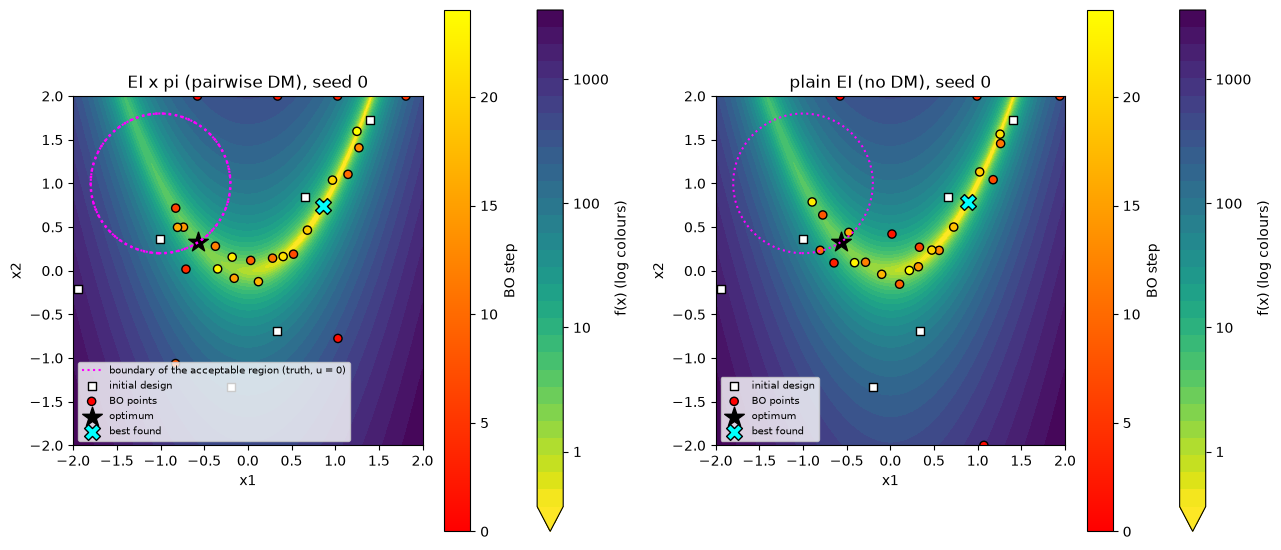

arm                       BO points with u > 0   best acceptable f per seed  (true best: 2.4608)
EI x pi (pairwise DM)                      12%   [  3.218   3.104 149.761]
plain EI (no DM)                           16%   [3.302 2.978 5.1  ]


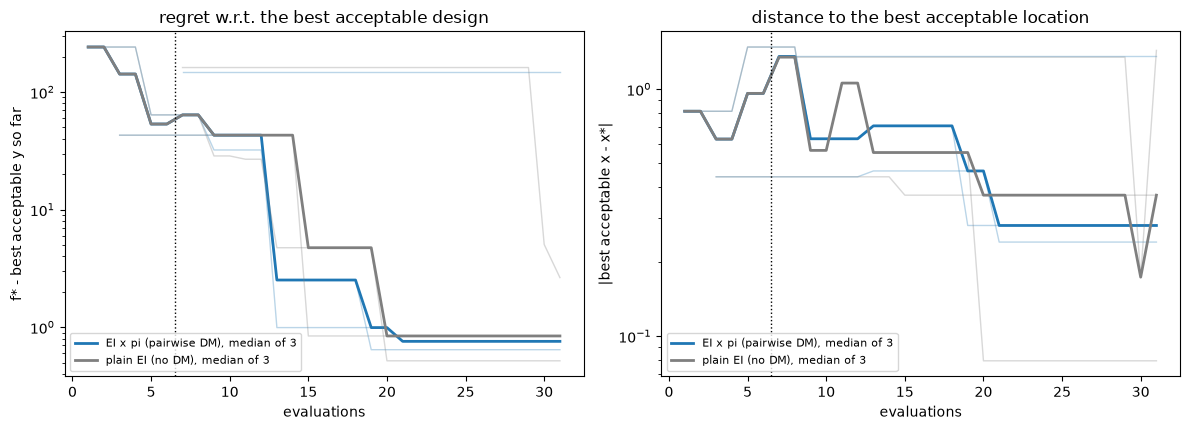

true best acceptable f: 2.4608 at [-0.565  0.33 ]


In [21]:
x_star, f_star = grid_optimum(neg_rosenbrock, ROSEN_BOUNDS, accept=lambda X: u_polynomial(X) > 0)


def best_acceptable_so_far(run):
    """For every k: regret and distance to x* of the best design with u > 0 among the first k evaluations (nan before
    the first one).  The true utility scores both arms the same way; plain EI has no DM, so its own incumbent ignores u."""
    values = np.where(u_polynomial(run.X) > 0, run.y, -np.inf)
    best_index = np.array([np.argmax(values[:k + 1]) for k in range(len(values))])
    found = np.isfinite(values[best_index])
    regret = np.where(found, np.maximum(f_star - run.y[best_index], 1e-9), np.nan)
    distance = np.where(found, np.linalg.norm(run.X[best_index] - x_star, axis=1), np.nan)
    return regret, distance


loop_runs = {"EI x pi (pairwise DM)": [], "plain EI (no DM)": []}
for seed in range(3):
    common = dict(seed=seed, f_optimum=f_star, x_optimum=x_star)
    loop_runs["EI x pi (pairwise DM)"].append(BayesianOptimizer(
        neg_rosenbrock, ROSEN_BOUNDS, comparer=PairwiseLabeler(u_polynomial),
        X_pref=initial_design(ROSEN_BOUNDS, 30, "sobol", seed=7 + seed), run_dir=RUNS / f"pairwise_seed{seed}",
        **common).run(25))
    loop_runs["plain EI (no DM)"].append(BayesianOptimizer(neg_rosenbrock, ROSEN_BOUNDS, **common).run(25))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))
for axis, (name, arm) in zip(axes, loop_runs.items()):
    arm[0].plot_points(ax=axis, background=bg, background_label="f(x)", background_scale="log", title=f"{name}, seed 0")
    axis.contour(map_x1, map_x2, u_polynomial(X_map).reshape(map_x1.shape), [0], colors="magenta", linestyles=":")
plt.tight_layout()
plt.show()

print(f"{'arm':24s} {'BO points with u > 0':>21s}   best acceptable f per seed  (true best: {-f_star:.4f})")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for (name, arm), colour in zip(loop_runs.items(), ("tab:blue", "tab:gray")):
    scores = np.array([best_acceptable_so_far(run) for run in arm])       # (seed, regret or distance, evaluation)
    evals = np.arange(1, scores.shape[2] + 1)
    for axis, curves in zip(axes, (scores[:, 0], scores[:, 1])):
        axis.plot(evals, curves.T, color=colour, alpha=0.3, lw=1)
        axis.plot(evals, np.nanmedian(curves, 0), color=colour, lw=2, label=f"{name}, median of {len(arm)}")
    share_accepted = np.mean([np.mean(u_polynomial(run.X[run.n_init:]) > 0) for run in arm])
    best_f = [-np.max(np.where(u_polynomial(run.X) > 0, run.y, -np.inf)) for run in arm]
    print(f"{name:24s} {share_accepted:21.0%}   {np.round(best_f, 3)}")
axes[0].set(yscale="log", xlabel="evaluations", ylabel="f* - best acceptable y so far", title="regret w.r.t. the best acceptable design")
axes[1].set(yscale="log", xlabel="evaluations", ylabel="|best acceptable x - x*|", title="distance to the best acceptable location")
for axis in axes:
    axis.axvline(arm[0].n_init + 0.5, color="k", ls=":", lw=1)
    axis.legend(fontsize=8)
plt.tight_layout()
plt.show()
print("true best acceptable f:", round(-f_star, 4), "at", np.round(x_star, 3))

What the acquisition function looked like when it chose evaluation 15 (pairwise arm, seed 0): log EI, log $\pi$ and their sum, which the loop maximises:

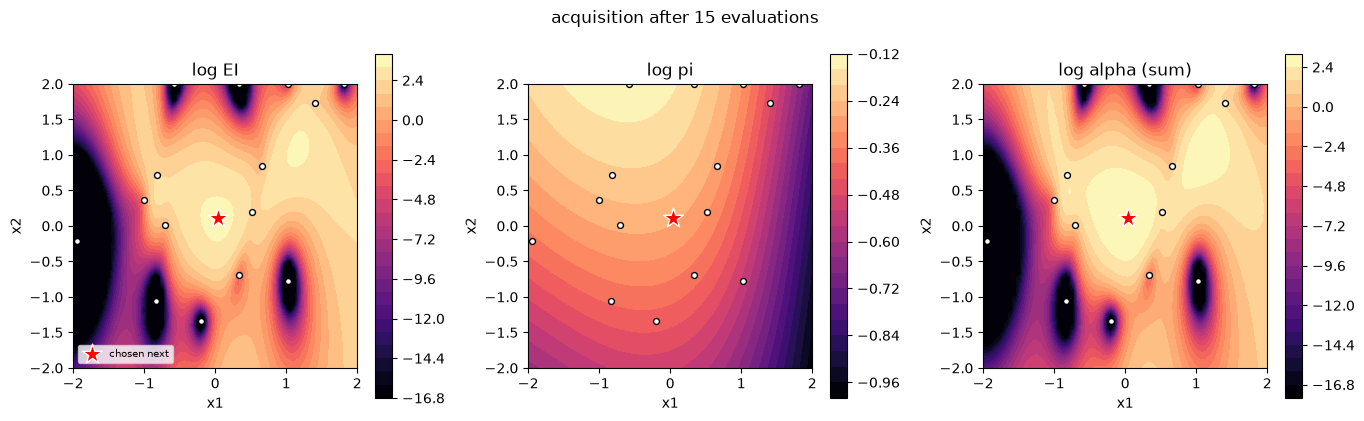

In [22]:
display(loop_runs["EI x pi (pairwise DM)"][0].plot_acquisition(n=15))